# Módulo 4 · De las células a los circuitos: excitación, inhibición y sincronía

La corteza tiene aproximadamente 80 % de neuronas excitatorias y 20 % de inhibitorias. Aquí 1000 células LIF se conectan al azar (10 %) y reciben ruido externo. Un parámetro, la fuerza relativa de la inhibición $g$, decide si el circuito dispara en **descargas síncronas** (inhibición débil) o de forma **asíncrona e irregular** (inhibición fuerte), como la corteza en vigilia (Brunel 2000).

**Gancho clínico.** Se piensa que muchas crisis epilépticas surgen cuando la inhibición falla y la excitación recluta poblaciones enteras a la vez. Este módulo permite observar esa transición.

Medidas: frecuencia media; CV de los intervalos entre disparos (0 = reloj, 1 = azar); índice de sincronía (varianza/media del conteo poblacional).

In [1]:
import sys, inspect
sys.path.insert(0, '..')            # make the neurosim package importable
import numpy as np
import matplotlib.pyplot as plt
import neurosim as ns
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

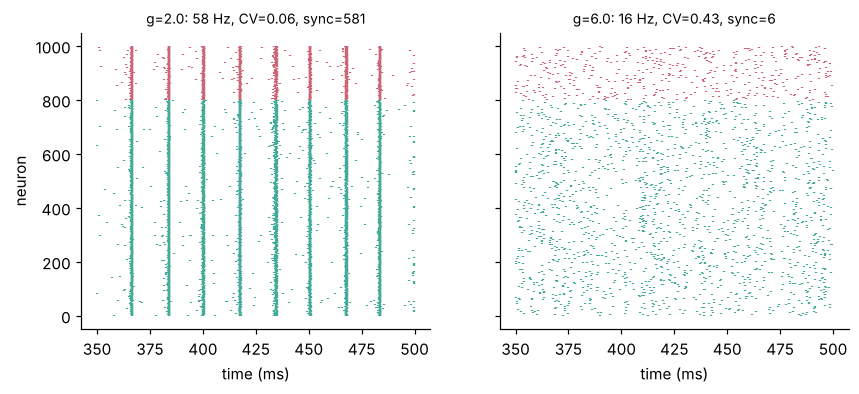

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharey=True)
for a_, (g, ext) in zip(ax, [(2.0, 8.0), (6.0, 7.0)]):
    net = ns.simulate_ei_network(g=g, ext_rate=ext, duration=500)
    st = ns.network_statistics(net)
    m = net['times'] > 350
    a_.scatter(net['times'][m], net['ids'][m], s=0.4, marker='|',
               c=np.where(net['ids'][m] < net['n_exc'], '#44AA99', '#CC6677'))
    a_.set_title(f"g={g}: {st['rate_hz']:.0f} Hz, CV={st['cv_isi']:.2f}, sync={st['synchrony']:.0f}", fontsize=9)
    a_.set_xlabel('time (ms)')
ax[0].set_ylabel('neuron'); plt.show()

## Ejercicios
1. Recorre `g` de 1 a 8 (tres semillas por valor) y grafica frecuencia, CV y sincronía frente a `g`. ¿Dónde está la transición?
2. Con `g=6`, sube `ext_rate` a 12. ¿Se mantiene el disparo irregular con una entrada fuerte?
3. Simula una "pérdida de interneuronas" reduciendo `n_inh` a 100 con `g=6`. ¿Qué ocurre?
4. ¿Por qué el disparo irregular necesita inhibición? Explícalo en dos oraciones.